<a href="https://colab.research.google.com/github/yuharani762-11/AI_SALES_ANALYTICS_TABLEAU/blob/main/AI_SALES_ANALYTICSuipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:

import kagglehub
import os

path = kagglehub.dataset_download(
    "vivek468/superstore-dataset-final"
)

print("Files available in the dataset:")

for root, folders, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(root, filename))


Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Files available in the dataset:
/kaggle/input/superstore-dataset-final/Sample - Superstore.csv


In [25]:

%pip install -q kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter
import pandas as pd

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "vivek468/superstore-dataset-final",
    "Sample - Superstore.csv",
    pandas_kwargs={"encoding": "latin1"}
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [26]:

import pandas as pd
import numpy as np

# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check column names and data types
print("\nDataset information:")
df.info()

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Remove duplicate rows
df = df.drop_duplicates().copy()

# 6. Clean column names
df.columns = df.columns.str.strip()

# 7. Convert date columns, if available
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# 8. Display cleaned data
print("\nCleaned dataset shape:", df.shape)
display(df.head())


Dataset shape: (9994, 21)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sale

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [27]:

# Summary statistics
display(df.describe(include="all").T)

# Total sales and profit
if "Sales" in df.columns and "Profit" in df.columns:
    print("Total Sales:", round(df["Sales"].sum(), 2))
    print("Total Profit:", round(df["Profit"].sum(), 2))

# Sales by category
if {"Category", "Sales"}.issubset(df.columns):
    print("\nSales by Category:")
    display(
        df.groupby("Category", as_index=False)["Sales"]
        .sum()
        .sort_values("Sales", ascending=False)
    )

# Profit by region
if {"Region", "Profit"}.issubset(df.columns):
    print("\nProfit by Region:")
    display(
        df.groupby("Region", as_index=False)["Profit"]
        .sum()
        .sort_values("Profit", ascending=False)
    )


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Row ID,9994.0,NaN,NaN,NaN,4997.5,1.0,2499.25,4997.5,7495.75,9994.0,2885.163629
Order ID,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,NaN,NaN,NaN,2016-04-30 00:07:12.259355648,2014-01-03 00:00:00,2015-05-23 00:00:00,2016-06-26 00:00:00,2017-05-14 00:00:00,2017-12-30 00:00:00,NaN
Ship Date,9994,NaN,NaN,NaN,2016-05-03 23:06:58.571142912,2014-01-07 00:00:00,2015-05-27 00:00:00,2016-06-29 00:00:00,2017-05-18 00:00:00,2018-01-05 00:00:00,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Total Sales: 2297200.86
Total Profit: 286397.02

Sales by Category:


,Category,Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320



Profit by Region:


,Region,Profit
3,West,108418.4489
1,East,91522.7800
2,South,46749.4303
0,Central,39706.3625


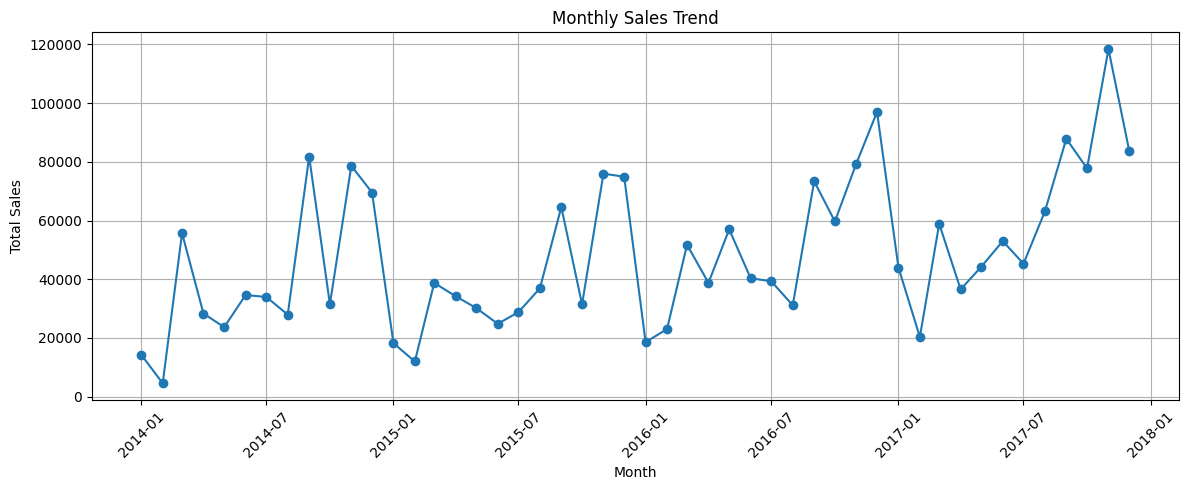

In [28]:

import matplotlib.pyplot as plt

# Monthly sales trend
if {"Order Date", "Sales"}.issubset(df.columns):
    monthly_sales = (
        df.dropna(subset=["Order Date"])
        .set_index("Order Date")["Sales"]
        .resample("MS")
        .sum()
    )

    plt.figure(figsize=(12, 5))
    plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
    plt.title("Monthly Sales Trend")
    plt.xlabel("Month")
    plt.ylabel("Total Sales")
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [29]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare monthly sales data
sales_data = df[["Order Date", "Sales"]].dropna().copy()
sales_data["Order Date"] = pd.to_datetime(sales_data["Order Date"])

monthly = (
    sales_data.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
    .asfreq("MS", fill_value=0)
    .reset_index()
)

monthly.columns = ["Date", "Sales"]
monthly = monthly.sort_values("Date").reset_index(drop=True)

# Create time-based features
monthly["Month"] = monthly["Date"].dt.month
monthly["Year"] = monthly["Date"].dt.year
monthly["TimeIndex"] = np.arange(len(monthly))

# Use previous months' sales as features
for lag in [1, 2, 3]:
    monthly[f"Lag_{lag}"] = monthly["Sales"].shift(lag)

model_data = monthly.dropna().copy()

print("Monthly data:")
display(monthly.tail())

print("Rows available for modeling:", len(model_data))


Monthly data:


,Date,Sales,Month,Year,TimeIndex,Lag_1,Lag_2,Lag_3
43,2017-08-01,63120.8880,8,2017,43,45264.4160,52981.7257,44261.1102
44,2017-09-01,87866.6520,9,2017,44,63120.8880,45264.4160,52981.7257
45,2017-10-01,77776.9232,10,2017,45,87866.6520,63120.8880,45264.4160
46,2017-11-01,118447.8250,11,2017,46,77776.9232,87866.6520,63120.8880
47,2017-12-01,83829.3188,12,2017,47,118447.8250,77776.9232,87866.6520


Rows available for modeling: 45


In [30]:

features = [
    "Month", "Year", "TimeIndex",
    "Lag_1", "Lag_2", "Lag_3"
]

if len(model_data) < 12:
    print("Not enough monthly observations for reliable forecasting.")
else:
    # Keep the latest 3 observed months for testing
    train = model_data.iloc[:-3]
    test = model_data.iloc[-3:]

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    model.fit(train[features], train["Sales"])
    predictions = model.predict(test[features])

    mae = mean_absolute_error(test["Sales"], predictions)
    rmse = np.sqrt(mean_squared_error(test["Sales"], predictions))

    print(f"Test MAE: {mae:,.2f}")
    print(f"Test RMSE: {rmse:,.2f}")

    results = pd.DataFrame({
        "Date": test["Date"].values,
        "Actual Sales": test["Sales"].values,
        "Predicted Sales": predictions
    })

    display(results)


Test MAE: 13,870.64
Test RMSE: 20,341.36


,Date,Actual Sales,Predicted Sales
0,2017-10-01,77776.9232,73286.362955
1,2017-11-01,118447.8250,83575.339053
2,2017-12-01,83829.3188,81580.440628


,Date,Forecast Sales
0,2018-01-01,42883.010203
1,2018-02-01,47213.419746
2,2018-03-01,55640.882680


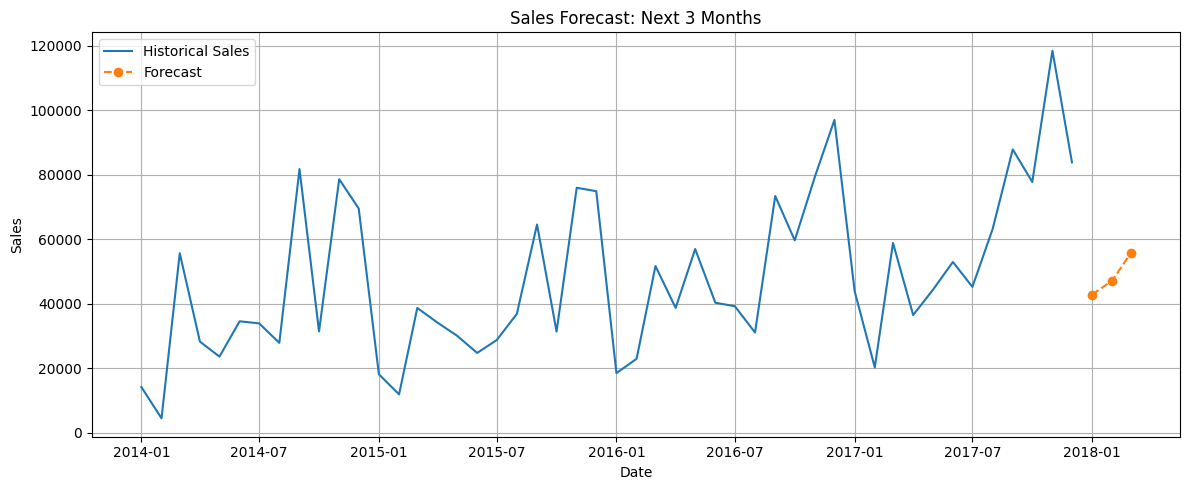

In [31]:

if len(model_data) >= 12:
    # Train on all available historical observations
    final_model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
    final_model.fit(model_data[features], model_data["Sales"])

    history = monthly["Sales"].tolist()
    last_date = monthly["Date"].max()
    forecast_rows = []

    for step in range(1, 4):
        future_date = last_date + pd.DateOffset(months=step)

        row = pd.DataFrame([{
            "Month": future_date.month,
            "Year": future_date.year,
            "TimeIndex": len(monthly) + step - 1,
            "Lag_1": history[-1],
            "Lag_2": history[-2],
            "Lag_3": history[-3]
        }])

        predicted_sales = max(
            0, float(final_model.predict(row[features])[0])
        )

        history.append(predicted_sales)
        forecast_rows.append({
            "Date": future_date,
            "Forecast Sales": predicted_sales
        })

    forecast = pd.DataFrame(forecast_rows)
    display(forecast)

    plt.figure(figsize=(12, 5))
    plt.plot(monthly["Date"], monthly["Sales"], label="Historical Sales")
    plt.plot(
        forecast["Date"], forecast["Forecast Sales"],
        marker="o", linestyle="--", label="Forecast"
    )
    plt.title("Sales Forecast: Next 3 Months")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [32]:

monthly.to_csv("monthly_sales.csv", index=False)
forecast.to_csv("sales_forecast.csv", index=False)

print("Exported monthly_sales.csv and sales_forecast.csv")


Exported monthly_sales.csv and sales_forecast.csv


In [33]:

from google.colab import files

monthly.to_csv("monthly_sales.csv", index=False)
forecast.to_csv("sales_forecast.csv", index=False)

files.download("monthly_sales.csv")
files.download("sales_forecast.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:

# Add lag columns to your monthly sales data
monthly["Lag_1"] = monthly["Sales"].shift(1)
monthly["Lag_2"] = monthly["Sales"].shift(2)
monthly["Lag_3"] = monthly["Sales"].shift(3)

# Save all columns into a new CSV file
monthly.to_csv("monthly_sales_with_lags.csv", index=False)

print("Columns created:")
print(monthly.columns.tolist())

display(monthly.head(10))


Columns created:
['Date', 'Sales', 'Month', 'Year', 'TimeIndex', 'Lag_1', 'Lag_2', 'Lag_3']


,Date,Sales,Month,Year,TimeIndex,Lag_1,Lag_2,Lag_3
0,2014-01-01,14236.8950,1,2014,0,NaN,NaN,NaN
1,2014-02-01,4519.8920,2,2014,1,14236.8950,NaN,NaN
2,2014-03-01,55691.0090,3,2014,2,4519.8920,14236.8950,NaN
3,2014-04-01,28295.3450,4,2014,3,55691.0090,4519.8920,14236.8950
4,2014-05-01,23648.2870,5,2014,4,28295.3450,55691.0090,4519.8920
5,2014-06-01,34595.1276,6,2014,5,23648.2870,28295.3450,55691.0090
6,2014-07-01,33946.3930,7,2014,6,34595.1276,23648.2870,28295.3450
7,2014-08-01,27909.4685,8,2014,7,33946.3930,34595.1276,23648.2870
8,2014-09-01,81777.3508,9,2014,8,27909.4685,33946.3930,34595.1276
9,2014-10-01,31453.3930,10,2014,9,81777.3508,27909.4685,33946.3930


In [36]:

import os
import glob
import pandas as pd

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

print("CSV files found:", csv_files)

if csv_files:
    csv_path = csv_files[0]
    original_df = pd.read_csv(csv_path, encoding="latin1")

    print("\nLoaded file:", os.path.basename(csv_path))
    print("Dataset shape:", original_df.shape)
    print("\nColumns:")
    print(original_df.columns.tolist())

    display(original_df.head())
else:
    print("No CSV files found. Check the files listed in Step 1.")


CSV files found: ['/kaggle/input/superstore-dataset-final/Sample - Superstore.csv']

Loaded file: Sample - Superstore.csv
Dataset shape: (9994, 21)

Columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [37]:

import kagglehub
import os
import glob
from google.colab import files

# Download the Kaggle dataset
path = kagglehub.dataset_download(
    "vivek468/superstore-dataset-final"
)

# Find CSV files
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", csv_files)

# Download the first CSV file
if csv_files:
    csv_path = csv_files[0]
    print("Downloading:", os.path.basename(csv_path))
    files.download(csv_path)
else:
    print("No CSV file found. Check the printed file list.")


Using Colab cache for faster access to the 'superstore-dataset-final' dataset.
CSV files found: ['/kaggle/input/superstore-dataset-final/Sample - Superstore.csv']
Downloading: Sample - Superstore.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>